In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.special import expit
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Defining binary treatment and outcome variable:
dataset["D"] = (dataset["treatment"] != 0).astype(int)

# Selection parameters:
S = "yob"
alpha = 0.0
gamma = 1.0
seed = 1465

rng = np.random.default_rng(seed)

# Standardizing year of birth (biased variable):
S_std = (dataset[S] - dataset[S].mean()) / dataset[S].std()

# Treated = +1, Control = -1
sign = np.where(dataset["D"] == 1, 1, -1)

# Logistic selection probability:
u = alpha + gamma * sign * S_std
p_keep = expit(u)

# Constructing biased sample:
keep = rng.uniform(size=len(dataset)) < p_keep
biased = dataset.loc[keep].copy()

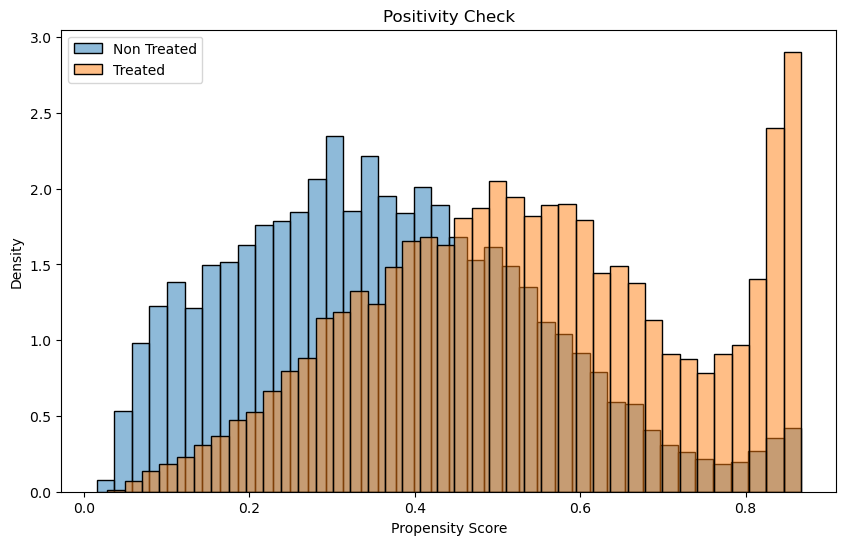

In [2]:
# Covariates for propensity score estimation:
ps_covariates = [
    "hh_size", "g2002", "g2000",
    "p2004", "p2002", "p2000",
    "sex", "yob"
]

# Standardizing covariates:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(biased[ps_covariates])

# Estimating propensity scores using logistic regression:
ps_model = LogisticRegression(
    C=1e6,
    max_iter=1000
)

ps_model.fit(X_scaled, biased["D"])

# Adding estimated propensity scores to biased dataset:
biased["propensity_score"] = ps_model.predict_proba(
    X_scaled
)[:, 1]

# Positivity check:
plt.figure(figsize=(10, 6))

sns.histplot(
    biased.query("D == 0")["propensity_score"],
    bins=40,
    stat="density",
    label="Non Treated",
    alpha=0.5
)

sns.histplot(
    biased.query("D == 1")["propensity_score"],
    bins=40,
    stat="density",
    label="Treated",
    alpha=0.5
)

plt.title("Positivity Check")
plt.xlabel("Propensity Score")
plt.ylabel("Density")
plt.legend()
plt.show()

In [4]:
from sklearn.neighbors import NearestNeighbors

# Separate treatment and control observations
treated = biased[biased["D"] == 1].copy()
control = biased[biased["D"] == 0].copy()

# Fit matching algorithm on control propensity scores
nn = NearestNeighbors(n_neighbors=1)

nn.fit(control[["propensity_score"]])

# Find closest control for each treated individual
distances, indices = nn.kneighbors(
    treated[["propensity_score"]]
)

# Extract matched controls
matched_control = control.iloc[indices.flatten()].copy()

# Align rows
matched_control.index = treated.index

# Match control observations to treated observations
nn_treated = NearestNeighbors(n_neighbors=1)

nn_treated.fit(treated[["propensity_score"]])

distances_c, indices_c = nn_treated.kneighbors(
    control[["propensity_score"]]
)

# Matched treated outcomes for each control observation
matched_treated_outcomes = (
    treated["voted"].to_numpy()[indices_c.flatten()]
)

# ATT

effects = (
    treated["voted"] - matched_control["voted"]
)

att = effects.mean()

# ATC
atc = (
    matched_treated_outcomes
    - control["voted"].to_numpy()
).mean()

# Calculate ATE using ATT and ATC
p_treated = len(treated) / len(biased)

ate_psm = p_treated * att + (1 - p_treated) * atc

print("PSM ATE:", ate_psm*100)


PSM ATE: 5.001453572882145


In [5]:
# Logistic regression of D on standardized S

S = "yob"
gamma = 1.0

# Standardize S using the original sample
S_mean = dataset[S].mean()
S_sd = dataset[S].std()

biased["S_std"] = (biased[S] - S_mean) / S_sd

# Fit logistic regression
X_logit = sm.add_constant(biased[["S_std"]])

logit_model = sm.Logit(
    biased["D"],
    X_logit
).fit()

# Display results
print(logit_model.summary())

# Compare coefficient to gamma
gamma_hat = logit_model.params["S_std"]

print("Chosen gamma:", gamma)
print("Estimated logistic coefficient:", gamma_hat)
print("Difference from gamma:", gamma_hat - gamma)


Optimization terminated successfully.
         Current function value: 0.593141
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                      D   No. Observations:               171990
Model:                          Logit   Df Residuals:                   171988
Method:                           MLE   Df Model:                            1
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                  0.1362
Time:                        15:02:53   Log-Likelihood:            -1.0201e+05
converged:                       True   LL-Null:                   -1.1810e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2320      0.005    -43.420      0.000      -0.242      -0.222
S_std          1.0091      0.